In [28]:
## Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
pd.set_option("display.max_columns", None)

In [29]:
## Load Data

df = pd.read_csv("retail_store_inventory.csv")

print(df.shape)

(73100, 15)


In [30]:
## Preview Dataset

df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [31]:
## Review Columns

df.columns.tolist()

['Date',
 'Store ID',
 'Product ID',
 'Category',
 'Region',
 'Inventory Level',
 'Units Sold',
 'Units Ordered',
 'Demand Forecast',
 'Price',
 'Discount',
 'Weather Condition',
 'Holiday/Promotion',
 'Competitor Pricing',
 'Seasonality']

In [32]:
## Dataset Overview

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  object 
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  object 
dtypes: float64(3), int64(5), object(7)
memory usage: 8.4+

In [33]:
## Missing Values

df.isnull().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64

In [34]:
## Summary Statistics

df.describe()

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000


In [35]:
## Create Revenue

df["Revenue"] = (
    df["Units Sold"]
    * df["Price"]
    * (1 - (df["Discount"] / 100))
)


In [36]:
## Verify Revenue

df[["Units Sold", "Price", "Discount", "Revenue"]].head()

,Units Sold,Price,Discount,Revenue
0,127,33.50,20,3403.600
1,150,63.01,20,7561.200
2,65,27.99,10,1637.415
3,61,32.72,10,1796.328
4,14,73.64,0,1030.960


In [37]:
## Total Revenue KPI

total_revenue = df["Revenue"].sum()

print(f"Total Revenue: ${total_revenue:,.2f}")

Total Revenue: $494,971,374.95


In [39]:
## Forecast Error

df["forecast_error"] = abs(
    df["Demand Forecast"]
    - df["Units Sold"]
)

In [40]:
## Inventory Health Score

df["inventory_health_score"] = (
    100 -
    (
        df["forecast_error"]
        /
        df["Demand Forecast"].replace(0, 1)
    ) * 100
)

In [41]:
## Stockout Flag

df["stockout_flag"] = np.where(
    df["Inventory Level"] == 0,
    1,
    0
)

In [42]:
## Executive KPI Scorecard

executive_summary = {
    "Total Revenue": round(df["Revenue"].sum(), 2),
    "Units Sold": int(df["Units Sold"].sum()),
    "Average Forecast Error":
        round(df["forecast_error"].mean(), 2),
    "Inventory Health Score":
        round(df["inventory_health_score"].mean(), 2)
}

executive_summary

{'Total Revenue': np.float64(494971374.95),
 'Units Sold': 9975582,
 'Average Forecast Error': np.float64(8.34),
 'Inventory Health Score': np.float64(85.43)}

In [43]:
## Revenue by Category

category_revenue = (
    df.groupby("Category")["Revenue"]
      .sum()
      .sort_values(ascending=False)
)

category_revenue

Category
Furniture      1.002308e+08
Groceries      9.994897e+07
Toys           9.872922e+07
Clothing       9.867678e+07
Electronics    9.738559e+07
Name: Revenue, dtype: float64

In [44]:
## Revenue by Region

region_revenue = (
    df.groupby("Region")["Revenue"]
      .sum()
      .sort_values(ascending=False)
)

region_revenue


Region
East     1.247922e+08
South    1.245674e+08
North    1.235437e+08
West     1.220681e+08
Name: Revenue, dtype: float64

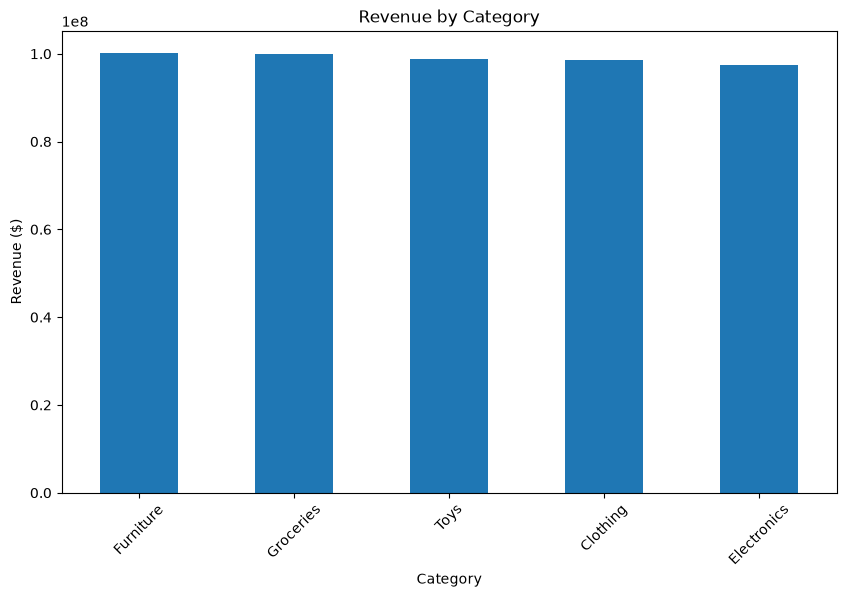

In [45]:
## Revenue by Category Chart

plt.figure(figsize=(10,6))

category_revenue.plot(kind="bar")

plt.title("Revenue by Category")
plt.ylabel("Revenue ($)")
plt.xlabel("Category")

plt.xticks(rotation=45)

plt.show()

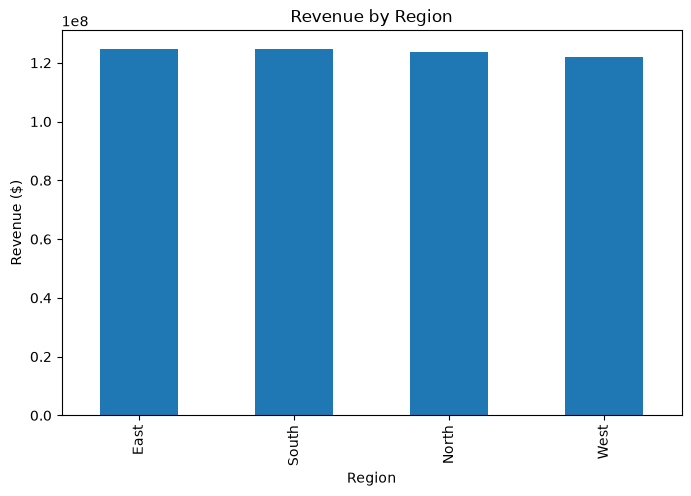

In [46]:
## Revenue by Region Chart

plt.figure(figsize=(8,5))

region_revenue.plot(kind="bar")

plt.title("Revenue by Region")
plt.ylabel("Revenue ($)")

plt.show()

In [47]:
## Top Categories by Units Sold

category_units = (
    df.groupby("Category")["Units Sold"]
      .sum()
      .sort_values(ascending=False)
)

category_units

Category
Furniture      2025017
Groceries      2000482
Clothing       1999166
Toys           1990485
Electronics    1960432
Name: Units Sold, dtype: int64

In [48]:
## Average Inventory by Category

avg_inventory = (
    df.groupby("Category")["Inventory Level"]
      .mean()
      .sort_values(ascending=False)
)

avg_inventory


Category
Furniture      275.816246
Groceries      275.755595
Clothing       274.597771
Toys           273.646862
Electronics    272.514427
Name: Inventory Level, dtype: float64

In [52]:
## Stockouts by Region

stockouts_by_region = (
    df.groupby("Region")["stockout_flag"]
      .sum()
      .sort_values(ascending=False)
)

stockouts_by_region

Region
East     0
North    0
South    0
West     0
Name: stockout_flag, dtype: int64

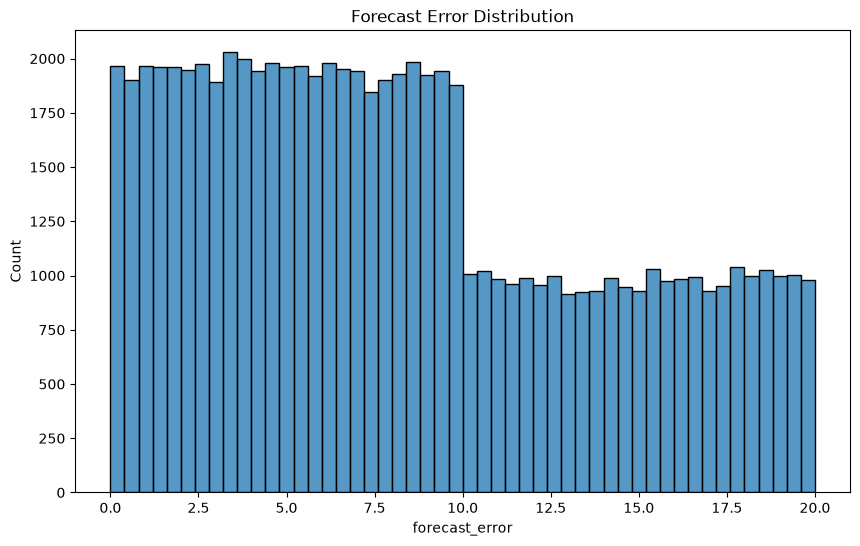

In [53]:
## Forecast Accuracy Distribution

plt.figure(figsize=(10,6))

sns.histplot(
    df["forecast_error"],
    bins=50
)

plt.title("Forecast Error Distribution")

plt.show()


In [54]:
## Correlation Matrix

corr_cols = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Demand Forecast",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Revenue",
    "forecast_error",
    "inventory_health_score"
]

corr = df[corr_cols].corr()

corr

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Competitor Pricing,Revenue,forecast_error,inventory_health_score
Inventory Level,1.000000,0.589995,0.001060,0.588561,0.009140,0.004889,0.009365,0.470514,0.005062,0.018930
Units Sold,0.589995,1.000000,-0.000930,0.996853,0.001082,0.002576,0.001259,0.793865,0.000190,0.039767
Units Ordered,0.001060,-0.000930,1.000000,-0.001102,0.004212,-0.000938,0.004596,0.002231,-0.001169,-0.004210
Demand Forecast,0.588561,0.996853,-0.001102,1.000000,0.000675,0.002338,0.000844,0.790960,0.060192,0.039496
Price,0.009140,0.001082,0.004212,0.000675,1.000000,0.001509,0.993900,0.468666,-0.005181,-0.004684
Discount,0.004889,0.002576,-0.000938,0.002338,0.001509,1.000000,0.001958,-0.073643,-0.000270,-0.000087
Competitor Pricing,0.009365,0.001259,0.004596,0.000844,0.993900,0.001958,1.000000,0.465947,-0.005149,-0.004689
Revenue,0.470514,0.793865,0.002231,0.790960,0.468666,-0.073643,0.465947,1.000000,-0.004721,0.031373
forecast_error,0.005062,0.000190,-0.001169,0.060192,-0.005181,-0.000270,-0.005149,-0.004721,1.000000,-0.020623
inventory_health_score,0.018930,0.039767,-0.004210,0.039496,-0.004684,-0.000087,-0.004689,0.031373,-0.020623,1.000000


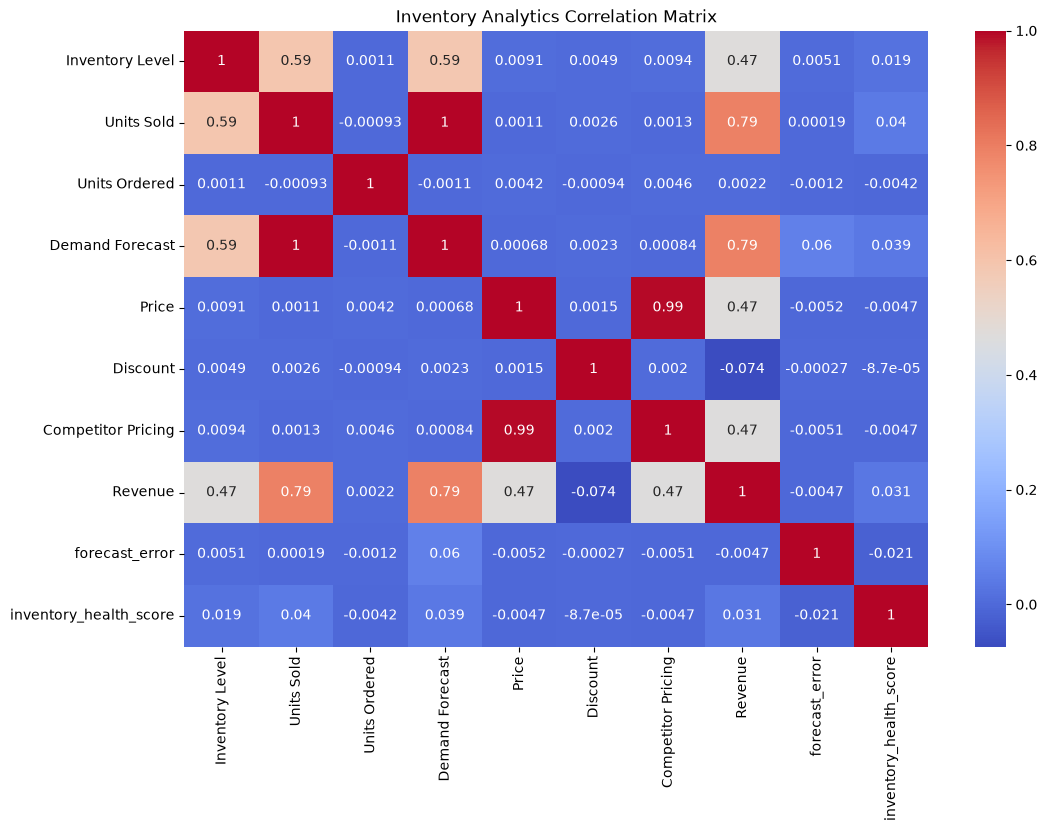

In [55]:
## Correlation Heatmap

plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=True
)

plt.title("Inventory Analytics Correlation Matrix")

plt.show()

In [56]:
## Save Dashboard Dataset

df.to_csv(
    "executive_dashboard_dataset.csv",
    index=False
)

print("Dashboard dataset saved.")

Dashboard dataset saved.


In [57]:
## Notebook Complete

print("Notebook 3 Complete")

Notebook 3 Complete
